# Una PD anclada con retiros de calificación informativos

**Pregunta:** Cuando una agencia retira calificaciones, y una calificación a punto de incumplir tiene más probabilidad de ser retirada,
¿cuánto se equivoca la PD de un grado leída de la página de transiciones, y puede un segundo conteo de los mismos incumplimientos, la
página de incumplimientos de la agencia, fijar la respuesta?

- **Nivel:** 4, métodos propuestos
- **Requisitos previos:** los notebooks 01, 02 y 10 de este tema (la PD por grado, sus intervalos, y la definición de incumplimiento
  y el estudio de retiros)
- **Tiempo de lectura:** unos 50 minutos

## Objetivos

Al terminar este notebook puedes:

- escribir la PD de un grado como función de k, la razón de probabilidades de que una calificación retirada en el año hubiera
  incumplido, y decir qué k supone cada tratamiento habitual de los retiros;
- leer el k anclado y el intervalo anclado desde un segundo conteo de incumplimientos, y el k de inflexión en que un grado pasaría al
  escalón siguiente;
- medir, sobre un generador de verdad conocida, con qué frecuencia el intervalo de cada tratamiento cubre la PD verdadera;
- probar si el k anclado es estable a lo largo de los años de las cohortes reales de CEREP, y decir dónde termina la afirmación del
  método.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. Un notebook nunca
instala nada por sí mismo. La celda siguiente importa lo que usa el notebook e imprime las versiones.

In [1]:
# Importar las herramientas, poner el estudio del caso en la ruta e imprimir las versiones con que corren
import importlib.metadata as md
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.generators.paths import RatingPaths
from riskvalidation.transitions import withdrawals as wd

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import c04_bounds as bnd

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))


riskvalidation 1.1.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El caso C04 lee la publicación CEREP de ESMA, los conteos de calificaciones de las entidades de las agencias en la UE (ESMA CEREP,
tablas transformadas por Contraste; https://registers.esma.europa.eu/cerep-publication/). Para cada cohorte anual y grado la página de
transiciones da los incumplimientos D, los sobrevivientes S y los retiros W; la página de incumplimientos cuenta, sobre su propia
cohorte Na, las calificaciones con un evento de incumplimiento en el año, A, retiradas o no. El documento versionado de S&P trae ambos
conteos por cohorte y grado; la familia de retiros trae el generador EM ajustado sobre los conteos agrupados de S&P, la verdad conocida
del estudio de más abajo.

In [2]:
# Leer los documentos versionados del caso C04: la entidad de S&P en la UE y el generador de la familia de retiros
C04 = ROOT / "data" / "derived" / "C04"
sp = json.loads((C04 / "sp.json").read_text(encoding="utf-8"))["outputs"]
family = json.loads((C04 / "withdrawals.json").read_text(encoding="utf-8"))["outputs"]
b = next(g for g in sp["withdrawal_bounds"]["grades"] if g["grade"] == "B")
p = b["pooled"]
d, s, w, a, na = p["defaults"], p["survivors"], p["withdrawn"], p["anchor_defaults"], p["anchor_cohort"]
print(sp["agency"]["name"], "|", len(b["cohorts"]), "cohortes anuales")
print(f"B, agrupada: D {d:,.0f} | S {s:,.0f} | W {w:,.0f} | A {a:,.0f} / Na {na:,.0f}")


Standard & Poor's Credit Market Services Europe Limited | 26 cohortes anuales
B, agrupada: D 372 | S 31,340 | W 4,451 | A 993 / Na 37,774


## Método

Una calificación retirada durante el año sale de la página de transiciones antes de su fin, así que la página no puede decir si
habría incumplido. Sea $k$ la razón de probabilidades de retiro de las calificaciones que incumplen en el año frente a las que no. De
las $W$ calificaciones retiradas, el número esperado que habría incumplido es $X(k) = W\,kD / (kD + S)$, y la PD del grado es

$$\mathrm{PD}(k) = \frac{D + X(k)}{N}, \qquad N = D + S + W.$$

$k = 1$ es la estimación habitual con los retiros eliminados, $D / (D + S)$; $k = 0$ los mantiene en el denominador como
sobrevivientes, $D / N$; $k \to \infty$ es la cota de Manski, $(D + W) / N$, el peor caso que permite la página de transiciones. Cada
tratamiento existente de los retiros es una elección de $k$ que nadie declara. `transitions.withdrawals` del motor calcula la familia
completa; la celda siguiente la evalúa para el grado B con los conteos agrupados de S&P.

In [3]:
# La PD del grado B como función de k, la razón de retiro antes del incumplimiento, con los conteos agrupados de S&P
ks = np.array([0, 0.5, 1, 2, 3, 5, 9, 15, 25, 50, 100])
curve = np.array([wd.withdrawal_pd([d], [s], [w], k)[0] for k in ks])
for k, value in zip(ks, curve):
    print(f"k {k:6.1f} | PD {100 * value:6.3f} %")
manski = (d + w) / (d + s + w)
print(f"cota de Manski (k infinito): {100 * manski:.3f} %")


k    0.0 | PD  1.029 %
k    0.5 | PD  1.101 %
k    1.0 | PD  1.173 %
k    2.0 | PD  1.314 %
k    3.0 | PD  1.452 %
k    5.0 | PD  1.718 %
k    9.0 | PD  2.217 %
k   15.0 | PD  2.889 %
k   25.0 | PD  3.845 %
k   50.0 | PD  5.613 %
k  100.0 | PD  7.709 %
cota de Manski (k infinito): 13.337 %


La familia es amplia. La PD del grado B es 1,029 % con los retiros mantenidos, 1,173 % con los retiros eliminados, 2,217 % con
$k = 9$ y 7,709 % con $k = 100$, y la cota de Manski, toda calificación retirada un incumplimiento, es 13,34 %. Los datos de la página
de transiciones por sí solos no pueden elegir entre ellas: todo punto de esta curva calza con los mismos conteos. Lo que puede elegir
es una segunda fuente que cuente los mismos incumplimientos.

La página de incumplimientos es esa fuente. Cuenta $A$ calificaciones con un evento de incumplimiento sobre su cohorte $N_a$,
retiradas o no. Leyendo $X$ desde ella, $X = N A / N_a - D$ (recortado a $[0, W]$), e invirtiendo $X(k)$ se obtiene el $k$ anclado;
el intervalo de Jeffreys de $A / N_a$ llevado por la misma función da su banda y el intervalo anclado de la PD. El $k$ de inflexión es
el valor en que $\mathrm{PD}(k)$ alcanza un umbral de decisión, aquí el límite de la escala maestra entre B y CCC-C, la media
geométrica de sus PD.

In [4]:
# El k anclado y el intervalo anclado de B, leídos del conteo de la página de incumplimientos, y el k de inflexión
res = wd.withdrawal_bounds([[s, d], [0.0, 0.0]], [w, 0.0], anchor_defaults=[a], anchor_obligors=[na], level=0.95)
an = res["anchor"]
k_band = f"{an['k'][0]:.2f} ({an['k_low'][0]:.2f} to {an['k_high'][0]:.2f})"
pd_band = f"{100 * an['pd'][0]:.3f} % ({100 * an['lower'][0]:.3f} to {100 * an['upper'][0]:.3f})"
print(f"k anclado: {k_band} | PD {pd_band} | flag {an['flag'][0]}")
threshold = b["tipping"]["threshold"]
tip = wd.tipping_k([d], [s], [w], [threshold])[0]
print(f"k de inflexión en el límite con CCC-C, {100 * threshold:.3f} %: k {tip:.2f}")


k anclado: 12.59 (11.18 to 14.10) | PD 2.629 % (2.315 to 2.967) | flag ok
k de inflexión en el límite con CCC-C, 3.076 %: k 16.81


La página de incumplimientos implica un $k$ anclado de 12,59, con una banda de 11,18 a 14,10: una calificación que incumple tiene
unas doce veces más probabilidad de ser retirada en su último año que una que sobrevive. La PD anclada de B es 2,629 %, entre 2,315 % y
2,967 %, más del doble del 1,173 % de la página de transiciones con los retiros eliminados. El $k$ de inflexión hacia CCC-C es 16,81,
sobre la banda anclada, así que con estos conteos B sigue siendo B. La figura pone las piezas en un mismo eje.

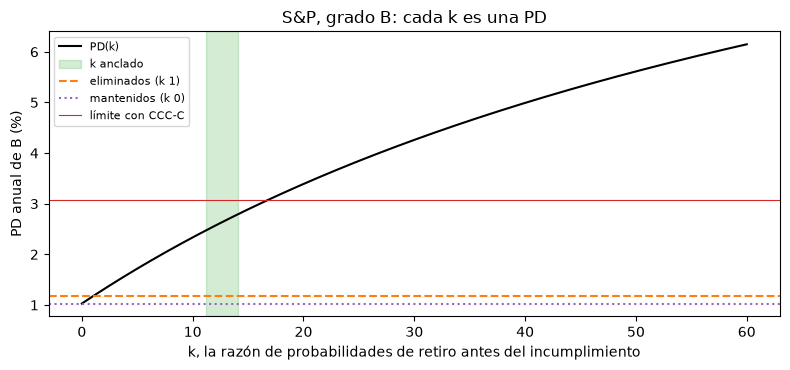

In [5]:
# Dibujar PD(k) con los dos tratamientos de CEREP, la banda anclada y el límite con CCC-C
grid = np.linspace(0, 60, 241)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(grid, [100 * wd.withdrawal_pd([d], [s], [w], k)[0] for k in grid], color="black", label="PD(k)")
ax.axvspan(an["k_low"][0], an["k_high"][0], color="tab:green", alpha=0.2, label="k anclado")
ax.axhline(100 * res["pd_industry"][0], color="tab:orange", linestyle="--", label="eliminados (k 1)")
ax.axhline(100 * res["pd_unfollowed"][0], color="tab:purple", linestyle=":", label="mantenidos (k 0)")
ax.axhline(100 * threshold, color="tab:red", linewidth=0.8, label="límite con CCC-C")
ax.set_xlabel("k, la razón de probabilidades de retiro antes del incumplimiento")
ax.set_ylabel("PD anual de B (%)")
ax.set_title("S&P, grado B: cada k es una PD")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


La curva negra es toda PD que permite la página de transiciones, subiendo desde el tratamiento de retiros mantenidos (punteado) por
el de retiros eliminados (discontinuo) a medida que crece $k$. La banda verde es donde la página de incumplimientos pone $k$; su PD queda
bastante sobre ambos tratamientos habituales y bajo el límite rojo con CCC-C, que la curva cruza solo con $k$ cerca de 17. Las dos
estimaciones habituales son puntos de la misma curva, en su extremo izquierdo, elegidos por convención y no por los datos.

## Comparación

Los métodos frente a los que se pone el intervalo anclado son los tres tratamientos de las calificaciones retiradas que usa la
práctica: eliminarlas (la página de transiciones, $k = 1$), mantenerlas en el denominador ($k = 0$, la convención de la página de
incumplimientos para la cohorte) y seguirlas hasta el fin del año (EBA/GL/2017/16, párrafo 76; aquí el oráculo, porque necesita el
resultado de cada calificación retirada, que ninguna página de transiciones tiene). Una cohorte real no tiene verdad conocida, así que
la comparación corre el estudio del caso, `pipeline.cases.c04_bounds.bounds_rung`, sobre el generador EM de los conteos de S&P con
retiro informativo con $k = 9$: 200 sorteos, cuatro diseños (la cohorte del primer año, cinco cohortes agrupadas, una segunda fuente
que cuenta solo el 70 % de los incumplimientos, y la cohorte del primer año diez veces mayor).

In [6]:
# Correr el estudio del caso sobre una verdad conocida: el generador EM de S&P, retiro informativo con k 9, 200 sorteos
q = np.array(family["generator"]["q"])
obligors = family["generator"]["obligors"]


def make_paths(qm, obl, years=5, **defect):
    times = tuple(float(t) for t in range(years + 1))
    return RatingPaths(qm, tuple(obl), horizon=float(years), snapshots=times, **defect)


study = bnd.bounds_rung(make_paths, q, obligors, seed=20261030, scale_seed=20261031, reps=200, informative=9.0,
                        withdrawal_rate=0.06, window=1.0)
coverage = {x["id"]: {t["id"]: t["coverage"][5]["rate"] for t in x["treatments"]} for x in study["designs"]}
print(f"PD anual verdadera de B: {100 * study['truth'][5]:.3f} %")
for design, row in coverage.items():
    print(f"{design:15s}", " | ".join(f"{t} {v:.3f}" for t, v in row.items()))


PD anual verdadera de B: 1.173 %
first_year      industry 0.840 | unfollowed 0.835 | followed 0.950 | anchored 1.000 | identified 1.000
pooled          industry 0.110 | unfollowed 0.030 | followed 0.740 | anchored 0.980 | identified 1.000
capture70       industry 0.840 | unfollowed 0.835 | followed 0.950 | anchored 0.995 | identified 1.000
first_year_x10  industry 0.215 | unfollowed 0.075 | followed 0.935 | anchored 1.000 | identified 1.000


En la cohorte del primer año los intervalos de retiros eliminados y mantenidos todavía cubren la PD verdadera de B, 1,173 %, en
84 % y 83,5 % de los sorteos: la cohorte es tan pequeña que el intervalo muestral es ancho. Agrupar cinco cohortes estrecha los
intervalos alrededor del valor equivocado, y cubren 11 % y 3 %; diez veces la cohorte hace lo mismo, 21,5 % y 7,5 %. El intervalo
anclado cubre el 100 % de los sorteos en la cohorte del primer año y el 98 % con cohortes agrupadas. La figura muestra los cuatro diseños
lado a lado.

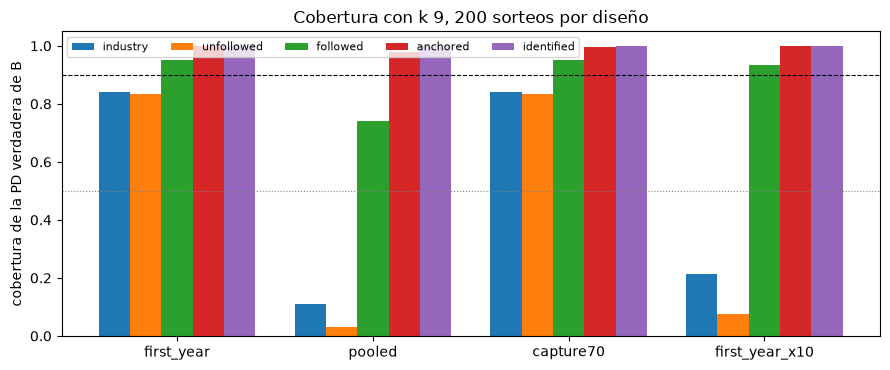

In [7]:
# Dibujar la cobertura de la PD verdadera de B por tratamiento en los cuatro diseños, con el 90 % fijado antes
treatments = ("industry", "unfollowed", "followed", "anchored", "identified")
designs = list(coverage)
x = np.arange(len(designs))
fig, ax = plt.subplots(figsize=(9, 3.8))
for j, t in enumerate(treatments):
    ax.bar(x + (j - 2) * 0.16, [coverage[dsg][t] for dsg in designs], 0.16, label=t)
ax.axhline(0.9, color="black", linestyle="--", linewidth=0.8)
ax.axhline(0.5, color="grey", linestyle=":", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(designs)
ax.set_ylabel("cobertura de la PD verdadera de B")
ax.set_title("Cobertura con k 9, 200 sorteos por diseño")
ax.legend(fontsize=8, ncol=5)
fig.tight_layout()
plt.show()


La línea discontinua es el 90 % que la afirmación pide al intervalo anclado, la punteada el 50 % bajo el cual la afirmación
espera que caigan los tratamientos existentes. Las barras ancladas quedan sobre el 90 % en todos los diseños, la banda identificada
(de $k = 0$ a la cota de Manski) lo cubre todo pero dice poco, y el oráculo de seguimiento queda entre 74 % y 95 %. Las barras de
retiros eliminados y mantenidos caen bajo el 50 % solo donde la muestra es lo bastante grande para que el sesgo supere al ruido:
agrupadas y diez veces mayor.

## Evidencia

La afirmación, fijada en el SDD antes de cualquier corrida, tiene tres partes: el intervalo anclado cubre la PD verdadera de B en al
menos 90 % de los sorteos con $k$ 1, 3 y 9; los tratamientos existentes la cubren en menos de 50 % con $k = 9$; y el $k$ anclado de las
cohortes reales es estable, es decir, al menos el 80 % de las bandas de las cohortes anuales contienen el $k$ agrupado. El estudio de
arriba habla de las dos primeras. La celda siguiente prueba la tercera sobre las cohortes reales de S&P del grado B con el motor, una
banda por año.

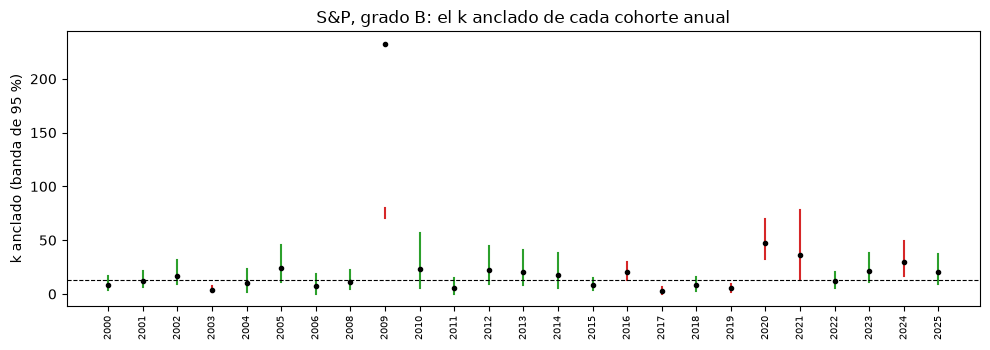

cohortes cuya banda contiene el k agrupado: 17 / 25 = 0.68


In [8]:
# Medir la estabilidad del k anclado: la banda de B de cada cohorte anual de S&P, frente al k agrupado
pooled_k = an["k"][0]
bands = []
for c in b["cohorts"]:
    r = wd.withdrawal_bounds([[c["survivors"], c["defaults"]], [0.0, 0.0]], [c["withdrawn"], 0.0],
                             anchor_defaults=[c["anchor_defaults"]], anchor_obligors=[c["anchor_cohort"]], level=0.95)
    lo, mid, hi = (float(r["anchor"][key][0]) for key in ("k_low", "k", "k_high"))
    if r["reason"][0] == "ok" and np.isfinite(lo) and not np.isnan(hi):
        bands.append((c["label"], lo, mid, hi))
inside = sum(lo <= pooled_k <= hi for _, lo, _, hi in bands)
fig, ax = plt.subplots(figsize=(10, 3.6))
for i, (_, lo, mid, hi) in enumerate(bands):
    ax.plot([i, i], [lo, min(hi, 80)], color="tab:green" if lo <= pooled_k <= hi else "tab:red")
    ax.plot(i, mid, "o", color="black", markersize=3)
ax.axhline(pooled_k, color="black", linestyle="--", linewidth=0.8)
ax.set_xticks(range(len(bands)))
ax.set_xticklabels([label for label, *_ in bands], rotation=90, fontsize=7)
ax.set_ylabel("k anclado (banda de 95 %)")
ax.set_title("S&P, grado B: el k anclado de cada cohorte anual")
fig.tight_layout()
plt.show()
print(f"cohortes cuya banda contiene el k agrupado: {inside} / {len(bands)} = {inside / len(bands):.2f}")


De las 25 cohortes anuales utilizables del grado B, 17 tienen una banda que contiene el $k$ anclado agrupado de 12,59: una
fracción de 0,68, bajo el 80 % que fijó la afirmación. Las barras rojas son los años cuya banda no lo contiene: por debajo en 2003, 2017
y 2019, por encima en 2009, 2016, 2020, 2021 y 2024. El $k$ anclado absorbe todo lo que hace que las dos páginas cuenten los
incumplimientos de distinto modo, no solo la informatividad de los retiros, y esa diferencia se mueve con el año. Siguen el veredicto
versionado y los otros grados.

In [9]:
# El veredicto del caso sobre el estudio versionado (200 sorteos por diseño y k) y el k anclado de cada grado
summary = bnd.verdict(family["rungs"])["summary"]
print({key: value for key, value in summary.items()})
for agency in ("sp", "fitch"):
    doc = json.loads((C04 / f"{agency}.json").read_text(encoding="utf-8"))["outputs"]
    for g in doc["withdrawal_bounds"]["grades"]:
        st, p = g["stability"], g["pooled"]
        if st and st["usable_cohorts"]:
            matrix = [[p["survivors"], p["defaults"]], [0.0, 0.0]]
            again = wd.withdrawal_bounds(matrix, [p["withdrawn"], 0.0], anchor_defaults=[p["anchor_defaults"]],
                                         anchor_obligors=[p["anchor_cohort"]])["anchor"]["k"][0]
            share = st["cohorts_containing_pooled_k"] / st["usable_cohorts"]
            print(f"{agency:5s} {g['grade']:5s} k {again:8.2f} | {share:.2f} | stable {st['stable']}")


{'refuted': False, 'anchored_covers_90': True, 'existing_under_50': False}
sp    AA    k    17.21 | 1.00 | stable True
sp    A     k     4.99 | 1.00 | stable True
sp    BBB   k     7.94 | 0.89 | stable True
sp    BB    k     7.50 | 0.88 | stable True
sp    B     k    12.59 | 0.68 | stable False
sp    CCC-C k    36.25 | 0.64 | stable False
fitch BBB   k   139.29 | 0.50 | stable False
fitch BB    k    24.73 | 1.00 | stable True
fitch B     k    31.65 | 0.70 | stable False
fitch CCC-C k    61.24 | 0.92 | stable True


El estudio versionado, 200 sorteos por diseño y $k$, dice lo mismo que la corrida de arriba: el intervalo anclado cubre al menos
el 90 % en todas partes, los tratamientos existentes no caen todos bajo el 50 % (la cohorte del primer año los deja sobre él), y la
parte de cobertura de la afirmación no queda refutada. La parte de estabilidad sí: en S&P el $k$ anclado es estable para AA, A, BBB y
BB y no para B y CCC-C; en Fitch es estable para BB y CCC-C y no para BBB y B. Así, el $k$ anclado es un $k$ condicionado a que las dos
páginas definan el incumplimiento igual, algo que ESMA no garantiza, y no una estimación de cuán informativos son los retiros.

## Resultados

**Respuesta:** La PD habitual del grado B es una elección de $k$, y con los conteos agrupados de S&P esa elección la mueve de 1,029 %
(retiros mantenidos) y 1,173 % (retiros eliminados) a 13,34 % (la cota de Manski). La página de incumplimientos ancla $k$ en 12,59 y la
PD en 2,629 %, más del doble de la cifra habitual. Sobre una verdad conocida con $k = 9$ el intervalo anclado cubre la PD verdadera en el
100 % de 200 sorteos de la cohorte del primer año y en el 98 % con cohortes agrupadas, donde los tratamientos de retiros eliminados y
mantenidos cubren 11 % y 3 % con cohortes agrupadas. En las cohortes reales el $k$ anclado de B se sostiene solo en 17 de 25 años, así que
no puede leerse como una propiedad estable de los retiros de la agencia.

## Resumen

- Todo tratamiento de las calificaciones retiradas es un valor de $k$ en $\mathrm{PD}(k) = (D + X(k))/N$; la página de transiciones
  por sí sola no puede elegir entre ellos.
- Un segundo conteo de los mismos incumplimientos ancla $k$; en el grado B de S&P da $k$ 12,59 y una PD de 2,629 %.
- Sobre una verdad conocida el intervalo anclado mantiene su cobertura donde eliminar o mantener los retiros la pierde.
- El $k$ anclado se mueve de un año a otro (17 de 25 cohortes de B contienen el valor agrupado), porque absorbe la diferencia entre las
  definiciones de incumplimiento de las dos páginas.

## Referencias

- ESMA, CEREP publication of credit rating agency ratings and transitions. https://registers.esma.europa.eu/cerep-publication/
- Manski, C. F. (1989), Anatomy of the selection problem, Journal of Human Resources 24(3). https://doi.org/10.2307/145818
- European Banking Authority (2017), Guidelines on PD estimation, LGD estimation and the treatment of defaulted exposures, EBA/GL/2017/16, párrafo 76.
- riskvalidation 1.1.0, `transitions.withdrawals` y su página. https://github.com/fsantibanezleal/CAOS_RiskValidation/blob/main/docs/transitions/06_withdrawal-bounds.md